In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [15]:
df = pd.read_csv(r"C:\Users\nhp\Documents\Healthcare_no_show_prediction\Dataset\medical_appointments.csv")

In [16]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [17]:
df.shape


(110527, 14)

In [18]:
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')

In [19]:
df.isnull().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

In [20]:
df = df.rename(columns={
    'Hipertension': 'Hypertension',
    'Handcap': 'Handicap',
    'No-show': 'No_Show'
})

In [21]:
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension',
       'Diabetes', 'Alcoholism', 'Handicap', 'SMS_received', 'No_Show'],
      dtype='object')

In [22]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

In [23]:
df[['ScheduledDay', 'AppointmentDay']].dtypes

ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object

In [24]:
df['Waiting_Days'] = (
    df['AppointmentDay'] - df['ScheduledDay']
).dt.days

In [25]:
df[['ScheduledDay', 'AppointmentDay', 'Waiting_Days']].head()

,ScheduledDay,AppointmentDay,Waiting_Days
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,-1
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,-1
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,-1
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,-1
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,-1


In [26]:
df['Appointment_Weekday'] = df['AppointmentDay'].dt.day_name()

In [27]:
df[['AppointmentDay', 'Appointment_Weekday']].head()

,AppointmentDay,Appointment_Weekday
0,2016-04-29 00:00:00+00:00,Friday
1,2016-04-29 00:00:00+00:00,Friday
2,2016-04-29 00:00:00+00:00,Friday
3,2016-04-29 00:00:00+00:00,Friday
4,2016-04-29 00:00:00+00:00,Friday


In [28]:
df['No_Show'] = df['No_Show'].map({
    'Yes': 1,
    'No': 0
})

In [29]:
df['No_Show'].value_counts()

No_Show
0    88208
1    22319
Name: count, dtype: int64

In [30]:
df['No_Show'].value_counts(normalize=True) * 100

No_Show
0    79.806744
1    20.193256
Name: proportion, dtype: float64

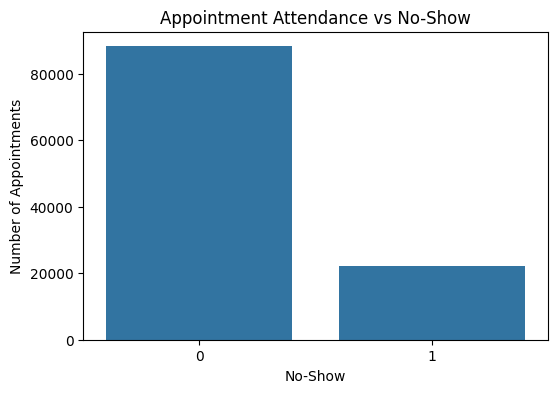

In [31]:
plt.figure(figsize=(6,4))

sns.countplot(x='No_Show', data=df)

plt.title('Appointment Attendance vs No-Show')
plt.xlabel('No-Show')
plt.ylabel('Number of Appointments')

plt.show()

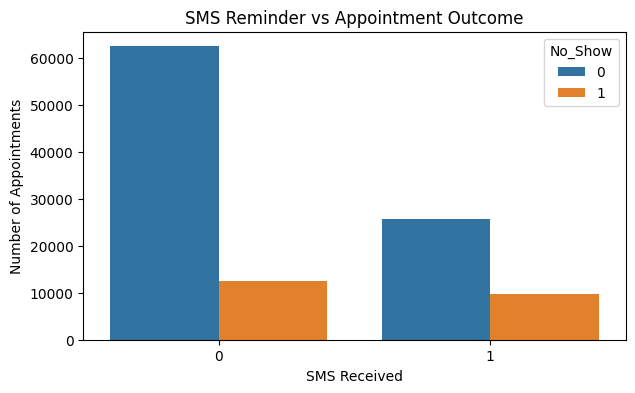

In [32]:
plt.figure(figsize=(7,4))

sns.countplot(
    x='SMS_received',
    hue='No_Show',
    data=df
)

plt.title('SMS Reminder vs Appointment Outcome')
plt.xlabel('SMS Received')
plt.ylabel('Number of Appointments')

plt.show()

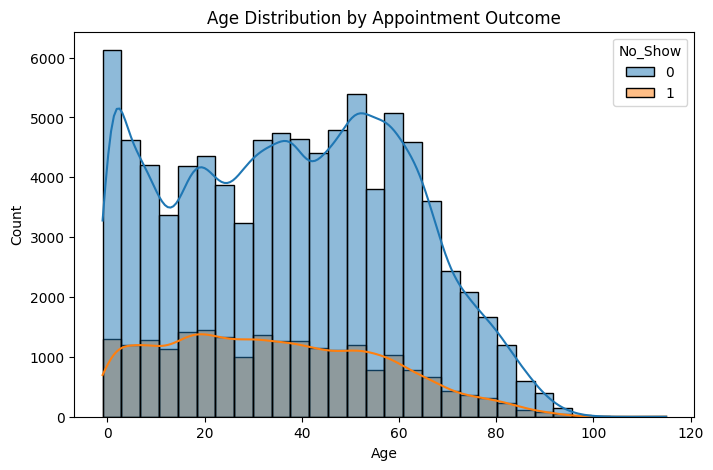

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='Age',
    hue='No_Show',
    bins=30,
    kde=True
)

plt.title('Age Distribution by Appointment Outcome')

plt.show()

In [34]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 30, 45, 60, 100],
    labels=[
        '0-18',
        '19-30',
        '31-45',
        '46-60',
        '60+'
    ]
)

In [35]:
df['Age_Group'].value_counts()

Age_Group
0-18     25327
46-60    23179
31-45    21954
60+      19755
19-30    16765
Name: count, dtype: int64

In [36]:
df['Scheduled_Weekday'] = df['ScheduledDay'].dt.day_name()

df['Appointment_Month'] = df['AppointmentDay'].dt.month

df['Appointment_Day'] = df['AppointmentDay'].dt.day

df['Is_Weekend'] = df['AppointmentDay'].dt.dayofweek.isin([5, 6]).astype(int)

In [37]:
model_df = df.drop([
    'PatientId',
    'AppointmentID',
    'ScheduledDay',
    'AppointmentDay',
    'Neighbourhood'
], axis=1)

In [38]:
model_df['Gender'] = model_df['Gender'].map({
    'F': 0,
    'M': 1
})


In [39]:
model_df = pd.get_dummies(
    model_df,
    columns=['Appointment_Weekday', 'Scheduled_Weekday', 'Age_Group'],
    drop_first=True
)

In [40]:
X = model_df.drop('No_Show', axis=1)
y = model_df['No_Show']

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [42]:

model = DecisionTreeClassifier(
    max_depth=6,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [43]:
y_pred = model.predict(X_test)

In [44]:
y_prob = model.predict_proba(X_test)[:, 1]

In [45]:
print(confusion_matrix(y_test, y_pred))

[[8531 9111]
 [ 617 3847]]


In [46]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
8,Waiting_Days,0.849933
1,Age,0.102076
7,SMS_received,0.013080
0,Gender,0.011481
12,Appointment_Weekday_Monday,0.004878
6,Handicap,0.002920
22,Age_Group_19-30,0.002217
2,Scholarship,0.002156
21,Scheduled_Weekday_Wednesday,0.002134
10,Appointment_Day,0.002132


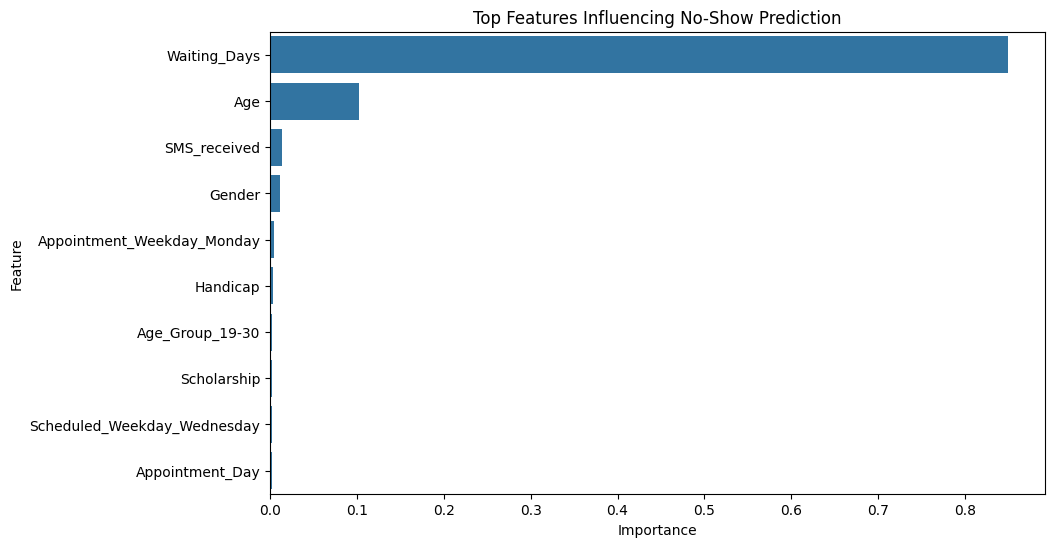

In [47]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top Features Influencing No-Show Prediction')

plt.show()

In [48]:
test_results = X_test.copy()

test_results['Actual_No_Show'] = y_test.values
test_results['Predicted_No_Show'] = y_pred
test_results['No_Show_Probability'] = y_prob